# Normalization Check for build_loaders_from_hf

This notebook loads and verifies whether normalization was applied to the image tensors. Means close to 0 and stds close to 1 per channel indicate successful normalization.

In [8]:
from pathlib import Path
from typing import Dict, Tuple, Iterable, Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from framework.dataset.load_for_training import load_eurosat_hf_splits, build_loaders_from_hf
from framework.utils.utils import load_config_toml

In [9]:
def compute_channel_stats(loader: torch.utils.data.DataLoader, num_batches: int = 5):
    means, vars_ = [], []
    processed = 0
    for batch in loader:
        x = batch[0] if isinstance(batch, (tuple, list)) else (
            batch.get('pixel_values') if isinstance(batch, dict) else batch)
        if isinstance(x, (list, tuple)):
            x = x[0]
        x = torch.as_tensor(x)
        if x.ndim == 3:
            x = x.unsqueeze(0)
        B, C, H, W = x.shape
        x = x.float().reshape(B, C, -1)
        means.append(x.mean(dim=(0, 2)).cpu().numpy())
        vars_.append(x.var(dim=(0, 2), unbiased=False).cpu().numpy())
        processed += 1
        if processed >= num_batches:
            break
    means = np.stack(means).mean(axis=0)
    stds = np.sqrt(np.stack(vars_).mean(axis=0))
    return means, stds



def _coerce_name_loader_items(obj) -> Iterable[Tuple[str, Any]]:
    # Dict case
    if isinstance(obj, dict):
        return obj.items()

    # List/tuple of (name, loader) pairs
    if isinstance(obj, (list, tuple)) and len(obj) > 0:
        if all(isinstance(x, tuple) and len(x) == 2 for x in obj):
            return obj
        # Plain sequence of loaders
        names = ["train", "val", "test", "extra1", "extra2"]
        return [(names[i], obj[i]) for i in range(min(len(obj), len(names)))]

    # Single loader
    return [("loader", obj)]

def _ensure_dataloader(maybe_loader):
    # If it already looks like a DataLoader, keep it
    if hasattr(maybe_loader, "__iter__") and hasattr(maybe_loader, "batch_size"):
        return maybe_loader

    # If it looks like a Dataset, wrap it
    if hasattr(maybe_loader, "__len__") and hasattr(maybe_loader, "__getitem__"):
        from torch.utils.data import DataLoader
        return DataLoader(maybe_loader, batch_size=32, shuffle=False)

    return maybe_loader  # best effort

def check_normalization_for_loaders(loaders, num_batches: int = 5) -> pd.DataFrame:
    rows = []
    for name, loader in _coerce_name_loader_items(loaders):
        try:
            loader = _ensure_dataloader(loader)
            means, stds = compute_channel_stats(loader, num_batches=num_batches)
            row = {"loader": name}
            for i, m in enumerate(means):
                row[f"mean_c{i}"] = float(m)
            for i, s in enumerate(stds):
                row[f"std_c{i}"] = float(s)
            rows.append(row)
        except Exception as e:
            rows.append({"loader": name, "error": str(e)})
    df = pd.DataFrame(rows)
    display(df)
    return df


def plot_means_stds(means: np.ndarray, stds: np.ndarray, title_prefix: str):
    s_means = pd.Series(means, index=[f'c{i}' for i in range(len(means))])
    s_stds = pd.Series(stds, index=[f'c{i}' for i in range(len(stds))])
    plt.figure();
    s_means.plot(kind='bar');
    plt.title(f'{title_prefix} - per channel mean');
    plt.xlabel('Channel');
    plt.ylabel('Value');
    plt.show()
    plt.figure();
    s_stds.plot(kind='bar');
    plt.title(f'{title_prefix} - per channel std');
    plt.xlabel('Channel');
    plt.ylabel('Value');
    plt.show()

In [10]:
CFG_PATH = Path("../configs/config.toml")

cfg = load_config_toml(CFG_PATH)
train_ds, val_ds, test_ds = load_eurosat_hf_splits(cfg.data.dataset_hf_repo_id)
loaders = build_loaders_from_hf(train_ds, val_ds,
                                cfg.training.batch_size,
                                cfg.data.image_size,
                                cfg.data.indices.calculated_indices,
                                cfg.data.augment,
                                normalize=cfg.data.normalize,
                                stats_samples=0,
                                selected_bands=cfg.data.indices.selected_bands,
                                num_workers=cfg.data.num_workers,
                                pin_memory=cfg.data.pin_memory)

,loader,mean_c0,mean_c1,mean_c2,mean_c3,mean_c4,mean_c5,mean_c6,mean_c7,mean_c8,...,std_c6,std_c7,std_c8,std_c9,std_c10,std_c11,std_c12,std_c13,std_c14,error
0,train,0.143072,0.110158,0.109151,0.112171,0.128792,0.125836,0.120134,0.119029,0.142318,...,0.939446,0.941573,1.013721,0.986238,1.004295,0.928048,0.953970,0.916948,0.974818,NaN
1,val,0.136358,0.295065,0.494327,0.614999,0.706753,0.712215,0.722786,0.673142,0.217552,...,0.775034,0.741984,0.730152,0.884491,1.006941,0.726142,0.722963,0.450542,1.029740,NaN
2,test,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"not enough values to unpack (expected 4, got 1)"
3,extra1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"not enough values to unpack (expected 4, got 1)"


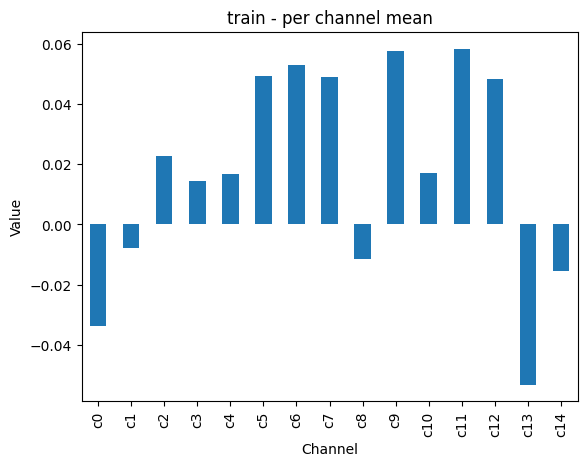

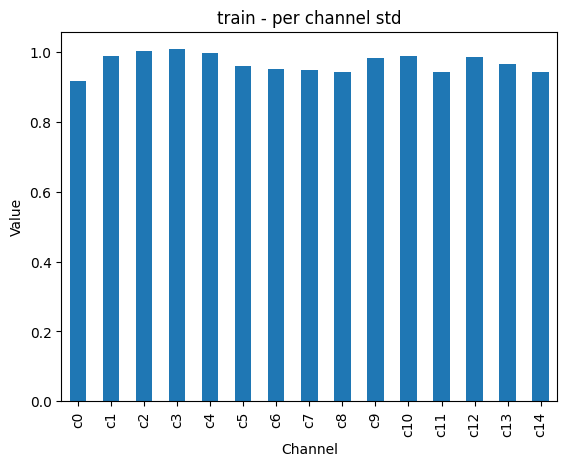

In [11]:
df = check_normalization_for_loaders(loaders, num_batches=5)

first_name, first_loader = next(iter(_coerce_name_loader_items(loaders)))
means, stds = compute_channel_stats(_ensure_dataloader(first_loader), num_batches=5)
plot_means_stds(means, stds, title_prefix=first_name)